In [ ]:
"""
codes_used_vs_sel_rate_by_alpha.py - experiment to show how logical selection rate varies with
noise scaling (alpha), grouped by number of codes used.
"""

import sys
sys.path.append("../")


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
import seaborn as sns
import pandas as pd

from pipeline.config import PipelineConfig
from pipeline import run_full_scan, run_extremal_scan, run_specific_scan
from simulator import ScaledNoiseModel, SimulatorConfig
from experiments.shared.example_circuits import n_ghz_state

plt.rcParams.update(
    {
        "font.family": "Helvetica",
        "font.sans-serif": "Helvetica",
        "font.size": 20,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "legend.fontsize": 20,
        "figure.titlesize": 20,
    }
)

# Sweep over alphas (noise scaling)
alphas = np.logspace(-1.5, 1.5, num=20)  # [0.001 ... 10] change bck to -1.5 to 1 and fix stim noise scaling
all_grouped_dfs = []

for alpha in alphas:
    print(f"Running full scan for alpha = {alpha:.3f}")

    # Build noise model
    noise_model = ScaledNoiseModel(alpha=alpha)
    sim_config = SimulatorConfig(noise_model=noise_model, repetitions=50_000).with_stim() #.with_distance_noise()

    # Configure pipeline
    config = PipelineConfig(
        sim_config=sim_config,
        verbose=False,
        fault_tolerant=False
    )

    perms = [
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (7,0), (8,0), (9,0), (10,0), (11,0), (12,0), (13,0), (14,0), (15,0), (16,0), (17,0), (18,0), (19,0)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (7,0), (8,0), (9,0), (10,0), (11,0), (12,0), (13,0), (14,0), (15,0), (16,0), (17,0), (18,0), (18,1)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (7,0), (8,0), (9,0), (10,0), (11,0), (12,0), (13,0), (14,0), (15,0), (16,0), (16,1), (17,0), (17,1)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (7,0), (8,0), (9,0), (10,0), (11,0), (12,0), (13,0), (14,0), (14,1), (15,0), (15,1), (16,0), (16,1)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (7,0), (8,0), (9,0), (10,0), (11,0), (12,0), (12,1), (13,0), (13,1), (14,0), (14,1), (15,0), (15,1)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (7,0), (8,0), (9,0), (10,0), (10,1), (11,0), (11,1), (12,0), (12,1), (13,0), (13,1), (14,0), (14,1)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (7,0), (8,0), (8,1), ( 9,0), ( 9,1), (10,0), (10,1), (11,0), (11,1), (12,0), (12,1), (13,0), (13,1)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (5,0), (6,0), (6,1), (7,0), (7,1), ( 8,0), ( 8,1), ( 9,0), ( 9,1), (10,0), (10,1), (11,0), (11,1), (12,0), (12,1)],
        [(0,0), (1,0), (2,0), (3,0), (4,0), (4,1), (5,0), (5,1), (6,0), (6,1), ( 7,0), ( 7,1), ( 8,0), ( 8,1), ( 9,0), ( 9,1), (10,0), (10,1), (11,0), (11,1)],
        [(0,0), (1,0), (2,0), (2,1), (3,0), (3,1), (4,0), (4,1), (5,0), (5,1), ( 6,0), ( 6,1), ( 7,0), ( 7,1), ( 8,0), ( 8,1), ( 9,0), ( 9,1), (10,0), (10,1)],
        [(0,0), (0,1), (1,0), (1,1), (2,0), (2,1), (3,0), (3,1), (4,0), (4,1), ( 5,0), ( 5,1), ( 6,0), ( 6,1), ( 7,0), ( 7,1), ( 8,0), ( 8,1), ( 9,0), ( 9,1)],
    ]

    program_circuit = n_ghz_state(20)["program"]

    # Run scan
    df = run_specific_scan(program_circuit, perms, config).dataframe.df

    # Group by number of codes used, average the logical selection rate
    grouped = df.groupby("codes_used")["logical_selection_rate"].mean().reset_index()
    grouped["alpha"] = alpha
    all_grouped_dfs.append(grouped)

# Combine all alpha sweeps into a single DataFrame
final_df = pd.concat(all_grouped_dfs, ignore_index=True)
# clipping for logit scale
final_df["logical_selection_rate"] = final_df["logical_selection_rate"].clip(1e-6, 1 - 1e-6)


Running full scan for alpha = 0.032


Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Simulating circuits:   0%|          | 0/11 [00:00<?, ? sim/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

...

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

Shots:   0%|          | 0/50000 [00:00<?, ?shot/s]

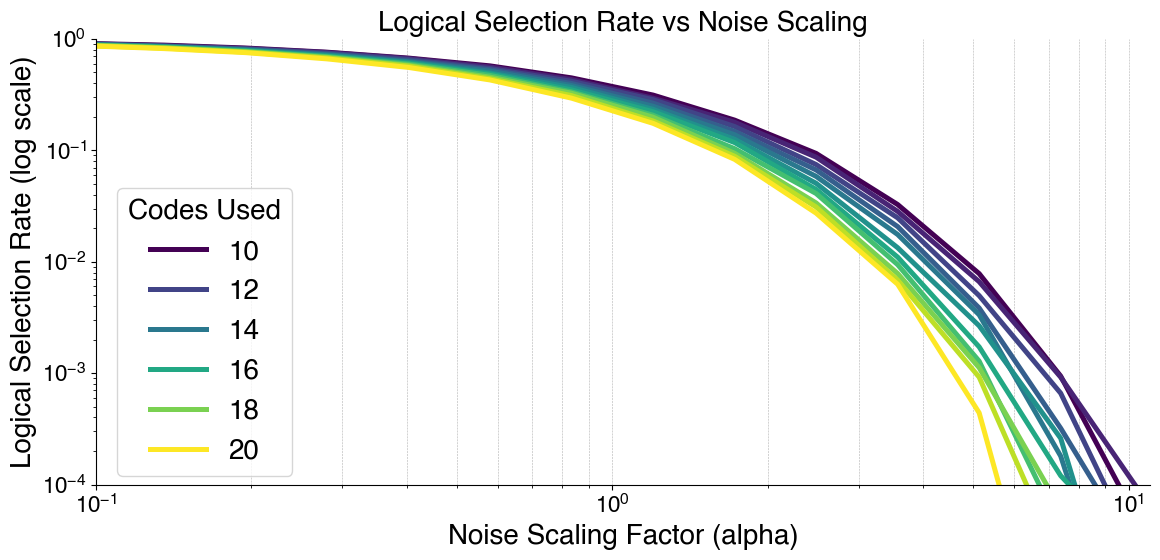

In [14]:
# Plot
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=final_df,
    x="alpha",
    y="logical_selection_rate",
    hue="codes_used",
    linewidth=3.6,
    ax=ax,
    palette="viridis"
)

ax.set_xscale("log")
ax.set_xlim(1e-1, 1.1e1)
ax.set_yscale("log")
ax.set_ylim(1e-4, 1)
ax.xaxis.set_major_locator(LogLocator(base=10, numticks=8))
# ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
ax.set_xlabel("Noise Scaling Factor (alpha)")
ax.set_ylabel("Logical Selection Rate (log scale)")
ax.set_title("Logical Selection Rate vs Noise Scaling")
ax.grid(True, which="both", axis="x", linestyle="--", linewidth=0.4)
# ax.grid(True, which="major", axis="y", linestyle="--", linewidth=0.4)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Optional: Legend formatting
# ax.legend(title="Codes Used", bbox_to_anchor=(1.02, 0.5), loc="center left", borderaxespad=0)
ax.legend(title="Codes Used", bbox_to_anchor=(.02, .02), loc="lower left", borderaxespad=0, frameon=True)

plt.tight_layout()

plt.savefig("logical_selection_rate_vs_alpha.svg", format="svg", dpi=300)

plt.show()
